# 🎙️ VoiceGuard — Week 1: Data + Feature Extraction

**Goal:** Download ASVspoof 2019 LA dataset inside Colab, extract audio features, save to Drive

**Dataset:** ASVspoof 2019 — the industry benchmark for deepfake audio detection
- **Real audio:** Genuine human speech
- **Fake audio:** AI-generated / voice cloned speech (11 different TTS/VC algorithms)

---
### Plan
1. Mount Drive + install packages
2. Download ASVspoof 2019 LA directly into Colab (no manual download needed)
3. Understand the dataset structure
4. Visualise real vs fake audio — what makes them different?
5. Extract features: MFCC, mel spectrogram, spectral features
6. Save feature dataset to Drive (~50MB, not 7GB)

In [1]:
# ── CELL 1: Mount Drive + Install packages ────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

!pip install librosa soundfile tqdm -q

print('✓ Drive mounted')
print('✓ Packages ready')

Mounted at /content/drive
✓ Drive mounted
✓ Packages ready


In [2]:
# ── CELL 2: Imports ───────────────────────────────────────────────────────
import os
import json
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from tqdm import tqdm
import warnings
import pickle
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 110
print('✓ All libraries loaded')
print(f'librosa version: {librosa.__version__}')

✓ All libraries loaded
librosa version: 0.11.0


---
## Step 1 — Download ASVspoof 2019 LA Dataset

We download directly into Colab using `wget` — no manual downloading needed.
We only need the **LA (Logical Access)** subset — this covers AI-generated speech.
PA (Physical Access) is for replay attacks which is out of scope.

**This will take 5–10 minutes** depending on Colab's network speed.

In [3]:
# ── CELL 3: Download dataset ──────────────────────────────────────────────
import subprocess

DATA_DIR = '/content/asvspoof'
os.makedirs(DATA_DIR, exist_ok=True)

print('Downloading ASVspoof 2019 LA dataset...')
print('This will take 5–10 minutes. Do not interrupt.\n')

# Download LA zip directly from the official mirror
download_url = 'https://datashare.ed.ac.uk/bitstream/handle/10283/3336/LA.zip'

result = subprocess.run(
    ['wget', '-q', '--show-progress', '-O', f'{DATA_DIR}/LA.zip', download_url],
    capture_output=False
)

if result.returncode == 0:
    size_gb = os.path.getsize(f'{DATA_DIR}/LA.zip') / 1024**3
    print(f'\n✓ Downloaded LA.zip ({size_gb:.2f} GB)')
else:
    print('Download failed — trying alternative mirror...')
    # Alternative: use Kaggle API if direct download fails
    print('\nIf download failed, run this instead:')
    print('!pip install kaggle -q')
    print('# Then upload kaggle.json and run:')
    print('# !kaggle datasets download -d awsaf49/asvpoof-2019-dataset')

This will take 5–10 minutes. Do not interrupt.


✓ Downloaded LA.zip (7.12 GB)


In [4]:
# ── CELL 4: Extract zip ───────────────────────────────────────────────────
print('Extracting LA.zip... (2–3 minutes)')
!unzip -q {DATA_DIR}/LA.zip -d {DATA_DIR}/

# Check structure
print('\nDataset structure:')
for root, dirs, files in os.walk(f'{DATA_DIR}/LA'):
    level = root.replace(f'{DATA_DIR}/LA', '').count(os.sep)
    indent = '  ' * level
    folder = os.path.basename(root)
    if level < 3:
        n_files = len(files)
        print(f'{indent}{folder}/ ({n_files} files)')

Extracting LA.zip... (2–3 minutes)

Dataset structure:
LA/ (1 files)
  ASVspoof2019_LA_asv_scores/ (2 files)
  ASVspoof2019_LA_eval/ (1 files)
    flac/ (71933 files)
  ASVspoof2019_LA_dev/ (1 files)
    flac/ (24986 files)
  ASVspoof2019_LA_cm_protocols/ (3 files)
  ASVspoof2019_LA_train/ (1 files)
    flac/ (25380 files)
  ASVspoof2019_LA_asv_protocols/ (10 files)


---
## Step 2 — Understand the Dataset

ASVspoof 2019 LA structure:
- `ASVspoof2019_LA_train/` — training audio files (.flac format)
- `ASVspoof2019_LA_dev/` — development/validation audio files
- `ASVspoof2019_LA_eval/` — evaluation audio files
- `ASVspoof2019_LA_cm_protocols/` — labels (genuine vs spoof, attack type)

**Label format:** Each line in the protocol file tells us:
`SPEAKER_ID  FILE_ID  ATTACK_TYPE  KEY`
where KEY = `bonafide` (real) or `spoof` (fake)

In [7]:

import os
import pandas as pd
import numpy as np

PROTOCOL_DIR = f'{DATA_DIR}/LA/ASVspoof2019_LA_cm_protocols'
TRAIN_AUDIO = f'{DATA_DIR}/LA/ASVspoof2019_LA_train/flac'
DEV_AUDIO = f'{DATA_DIR}/LA/ASVspoof2019_LA_dev/flac'

train_protocol = f'{PROTOCOL_DIR}/ASVspoof2019.LA.cm.train.trn.txt'
dev_protocol = f'{PROTOCOL_DIR}/ASVspoof2019.LA.cm.dev.trl.txt'

def load_protocol(path):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Protocol not found: {path}")

    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            parts = line.split()
            if not parts:
                continue

            # Some distributed versions contain an extra placeholder field.
            if len(parts) == 4:
                speaker_id, file_id, attack_type, label = parts
            elif len(parts) == 5:
                speaker_id, file_id, field3, field4, label = parts
                attack_type = field3 if field3 != "-" else field4
            else:
                raise ValueError(
                    f"Unexpected format at line {line_number}: {parts}"
                )

            if label not in {"bonafide", "spoof"}:
                raise ValueError(
                    f"Unexpected label at line {line_number}: {label}"
                )

            rows.append([speaker_id, file_id, attack_type, label])

    df = pd.DataFrame(
        rows,
        columns=["speaker_id", "file_id", "attack_type", "label"]
    )
    df["is_fake"] = (df["label"] == "spoof").astype(np.int64)
    return df

train_df = load_protocol(train_protocol)
dev_df = load_protocol(dev_protocol)

print("Training files:", len(train_df))
print(train_df["label"].value_counts())
print("\nDevelopment files:", len(dev_df))
print(dev_df["label"].value_counts())
print("\nAttack/system IDs:", train_df["attack_type"].nunique())


Training files: 25380
label
spoof       22800
bonafide     2580
Name: count, dtype: int64

Development files: 24844
label
spoof       22296
bonafide     2548
Name: count, dtype: int64

Attack/system IDs: 7


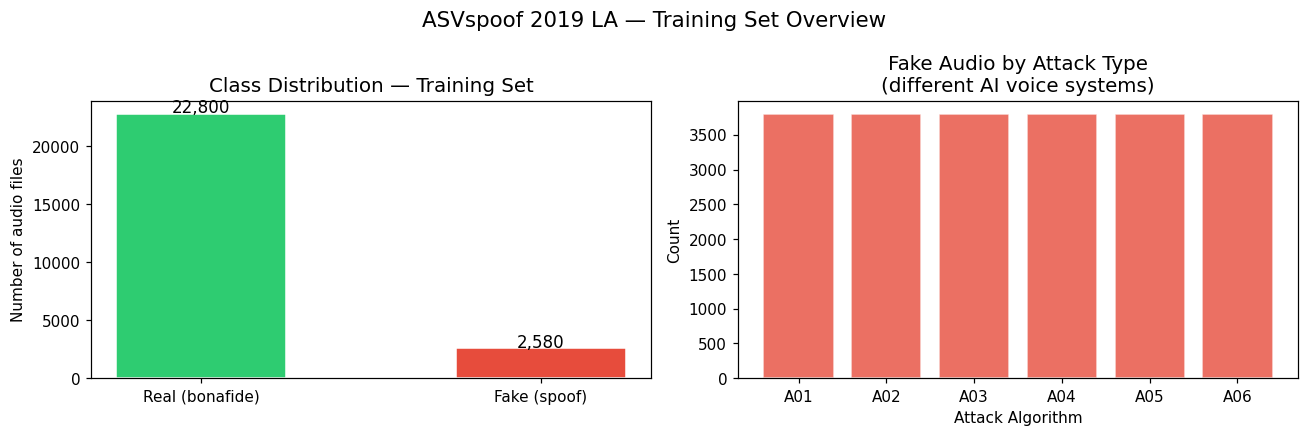

Each attack type = a different AI voice synthesis algorithm
A6 = Griffin-Lim, A7 = waveform concat, A8-A19 = neural TTS/VC systems


In [8]:
# ── CELL 6: Class balance ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
counts = train_df['label'].value_counts()
axes[0].bar(['Real (bonafide)', 'Fake (spoof)'], counts.values,
            color=['#2ECC71', '#E74C3C'], edgecolor='white', width=0.5)
axes[0].set_title('Class Distribution — Training Set', fontsize=13)
axes[0].set_ylabel('Number of audio files')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 100, f'{v:,}', ha='center', fontsize=11)

# Attack type breakdown
attack_counts = train_df[train_df['label']=='spoof']['attack_type'].value_counts()
axes[1].bar(attack_counts.index, attack_counts.values,
            color='#E74C3C', alpha=0.8, edgecolor='white')
axes[1].set_title('Fake Audio by Attack Type\n(different AI voice systems)', fontsize=13)
axes[1].set_ylabel('Count')
axes[1].set_xlabel('Attack Algorithm')

plt.suptitle('ASVspoof 2019 LA — Training Set Overview', fontsize=14)
plt.tight_layout()
plt.show()

print('Each attack type = a different AI voice synthesis algorithm')
print('A6 = Griffin-Lim, A7 = waveform concat, A8-A19 = neural TTS/VC systems')

---
## Step 3 — Visualise Real vs Fake Audio

**This is the most important section of Week 1.**

Before building any model, we need to *see* what makes real and fake audio different.
We'll look at:
- **Waveform** — the raw audio signal
- **Mel Spectrogram** — frequency content over time (what the CNN will learn from)
- **MFCC** — Mel Frequency Cepstral Coefficients (captures vocal tract shape)

Key insight: AI-generated voices tend to have:
- Unnaturally smooth spectrograms (no micro-variations)
- Missing high-frequency components (>8kHz often flat)
- Overly consistent energy patterns (humans breathe, pause, vary)

In [9]:
# ── CELL 7: Load one real + one fake audio sample ─────────────────────────
# Get file IDs
real_file = train_df[train_df['label']=='bonafide']['file_id'].iloc[0]
fake_file = train_df[train_df['label']=='spoof']['file_id'].iloc[0]

real_path = f'{TRAIN_AUDIO}/{real_file}.flac'
fake_path = f'{TRAIN_AUDIO}/{fake_file}.flac'

# Load audio (sr=16000 is standard for speech)
real_audio, sr = librosa.load(real_path, sr=16000)
fake_audio, _  = librosa.load(fake_path, sr=16000)

print(f'Sample rate    : {sr} Hz')
print(f'Real audio     : {real_file} ({len(real_audio)/sr:.2f} seconds)')
print(f'Fake audio     : {fake_file} ({len(fake_audio)/sr:.2f} seconds)')
print(f'\nReal audio range: [{real_audio.min():.3f}, {real_audio.max():.3f}]')
print(f'Fake audio range: [{fake_audio.min():.3f}, {fake_audio.max():.3f}]')

Sample rate    : 16000 Hz
Real audio     : LA_T_1138215 (3.46 seconds)
Fake audio     : LA_T_1004644 (1.92 seconds)

Real audio range: [-1.000, 0.974]
Fake audio range: [-1.000, 0.611]


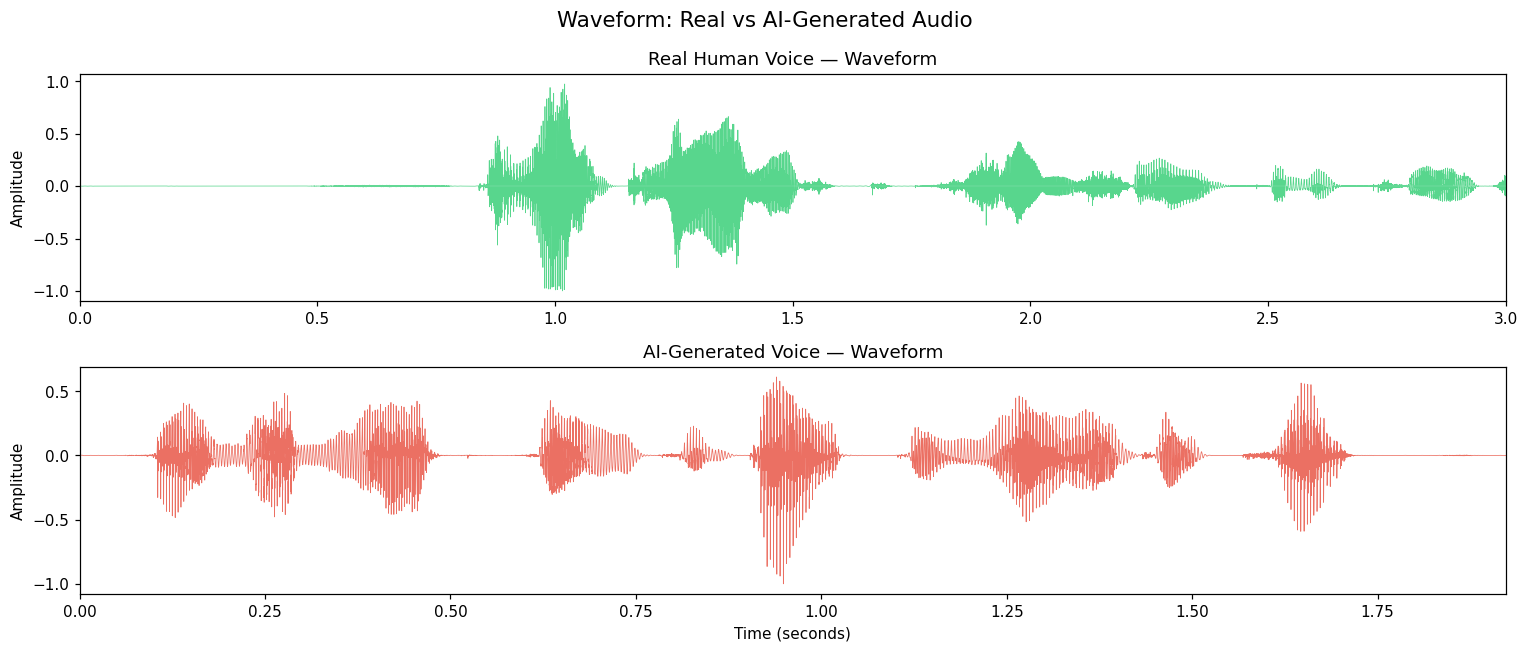

Look for: irregular amplitude variations in real voice (breathing, natural variation)
AI voices often show unnaturally consistent amplitude patterns


In [10]:
# ── CELL 8: Waveform comparison ───────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# Real
times_real = np.linspace(0, len(real_audio)/sr, len(real_audio))
axes[0].plot(times_real, real_audio, color='#2ECC71', linewidth=0.5, alpha=0.8)
axes[0].set_title('Real Human Voice — Waveform', fontsize=12)
axes[0].set_ylabel('Amplitude')
axes[0].set_xlim([0, min(3, len(real_audio)/sr)])
axes[0].axhline(y=0, color='white', linewidth=0.3, alpha=0.3)

# Fake
times_fake = np.linspace(0, len(fake_audio)/sr, len(fake_audio))
axes[1].plot(times_fake, fake_audio, color='#E74C3C', linewidth=0.5, alpha=0.8)
axes[1].set_title('AI-Generated Voice — Waveform', fontsize=12)
axes[1].set_ylabel('Amplitude')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_xlim([0, min(3, len(fake_audio)/sr)])

plt.suptitle('Waveform: Real vs AI-Generated Audio', fontsize=14)
plt.tight_layout()
plt.show()
print('Look for: irregular amplitude variations in real voice (breathing, natural variation)')
print('AI voices often show unnaturally consistent amplitude patterns')

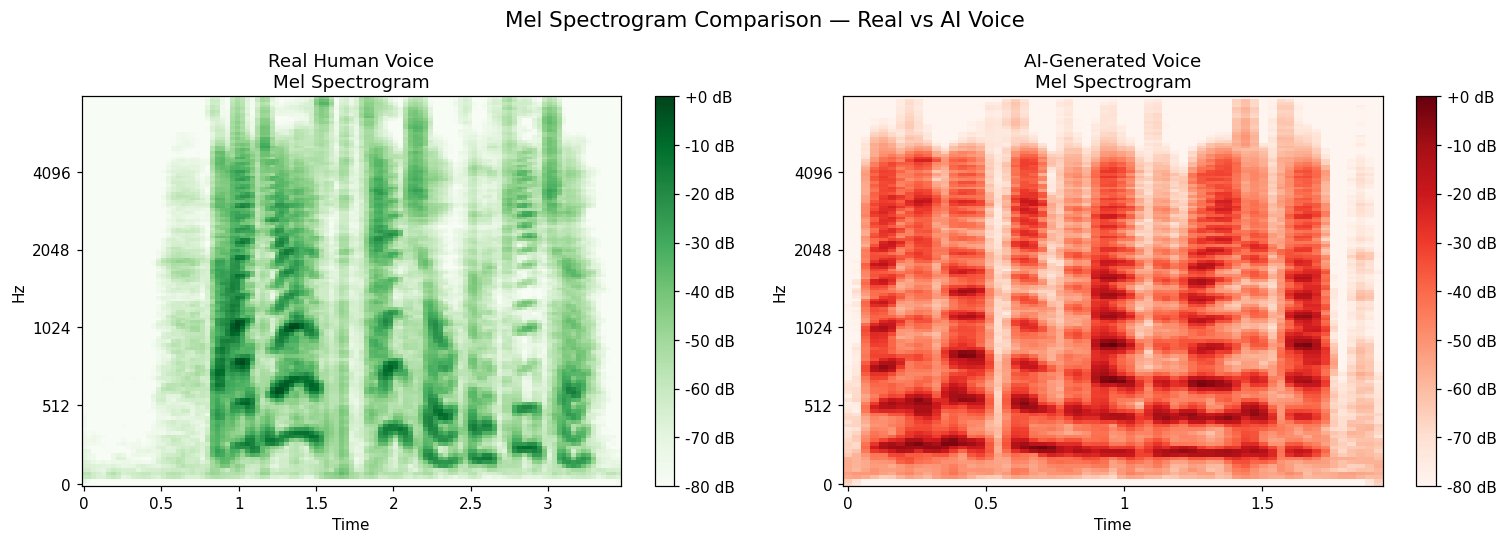

Key differences to look for:
  Real: irregular frequency patterns, visible breath pauses, natural transitions
  Fake: smoother patterns, unnaturally consistent energy, sharp cut-offs


In [11]:
# ── CELL 9: Mel Spectrogram comparison ───────────────────────────────────
# This is what the CNN will learn from
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, audio, title, color in zip(
    axes,
    [real_audio, fake_audio],
    ['Real Human Voice', 'AI-Generated Voice'],
    ['Greens', 'Reds']
):
    mel_spec = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_mels=128, fmax=8000
    )
    mel_db = librosa.power_to_db(mel_spec, ref=np.max)
    img = librosa.display.specshow(
        mel_db, sr=sr, x_axis='time', y_axis='mel',
        fmax=8000, ax=ax, cmap=color
    )
    ax.set_title(f'{title}\nMel Spectrogram', fontsize=12)
    fig.colorbar(img, ax=ax, format='%+2.0f dB')

plt.suptitle('Mel Spectrogram Comparison — Real vs AI Voice', fontsize=14)
plt.tight_layout()
plt.show()
print('Key differences to look for:')
print('  Real: irregular frequency patterns, visible breath pauses, natural transitions')
print('  Fake: smoother patterns, unnaturally consistent energy, sharp cut-offs')

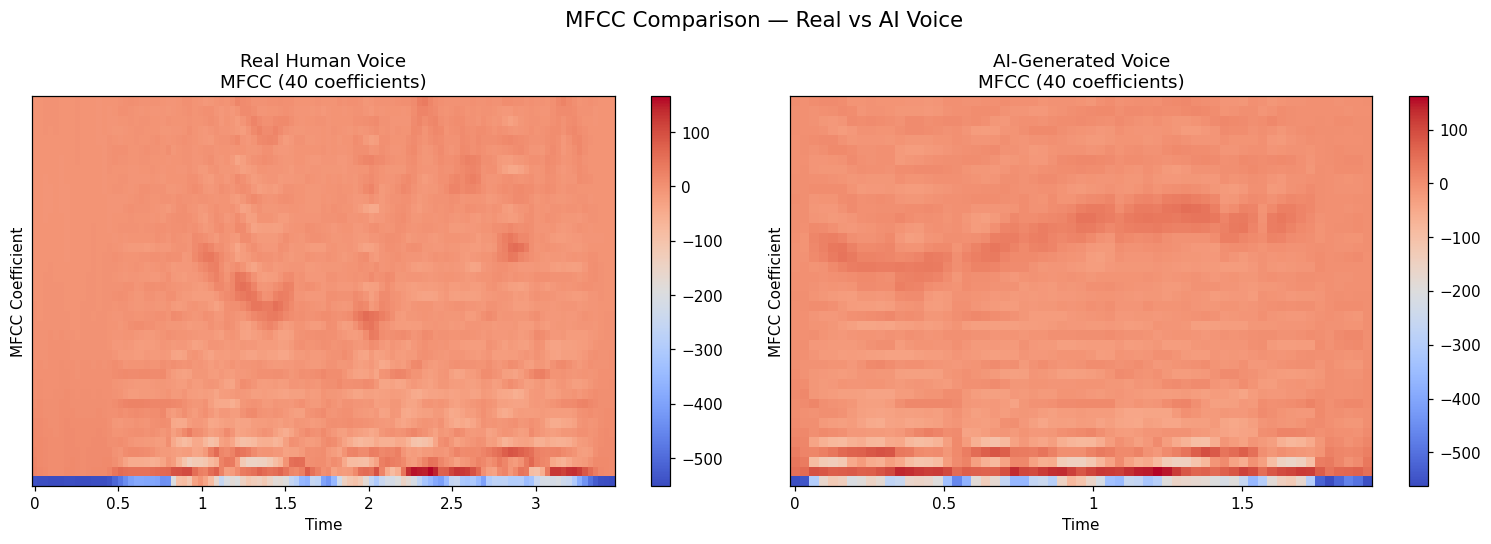

MFCC captures vocal tract shape — essentially a fingerprint of how sound is produced
AI voices have different MFCC patterns because they synthesise rather than produce sound


In [12]:
# ── CELL 10: MFCC comparison ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, audio, title in zip(
    axes,
    [real_audio, fake_audio],
    ['Real Human Voice', 'AI-Generated Voice']
):
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)
    img = librosa.display.specshow(
        mfcc, sr=sr, x_axis='time', ax=ax, cmap='coolwarm'
    )
    ax.set_title(f'{title}\nMFCC (40 coefficients)', fontsize=12)
    ax.set_ylabel('MFCC Coefficient')
    fig.colorbar(img, ax=ax)

plt.suptitle('MFCC Comparison — Real vs AI Voice', fontsize=14)
plt.tight_layout()
plt.show()
print('MFCC captures vocal tract shape — essentially a fingerprint of how sound is produced')
print('AI voices have different MFCC patterns because they synthesise rather than produce sound')

---
## Step 4 — Feature Extraction Pipeline

For each audio file, the current baseline extractor computes a fixed-length summary vector:

| Feature family | Values |
|---|---:|
| MFCC mean + standard deviation | 80 |
| MFCC delta mean + standard deviation | 80 |
| Log-mel mean + standard deviation (128 bands) | 256 |
| Spectral centroid, rolloff, zero-crossing rate, RMS (mean + std each) | 8 |
| Chroma mean + standard deviation (12 bins) | 24 |
| Spectral contrast mean (7 bands by default) | 7 |
| **Total expected** | **455** |

These summary features are for a classical baseline. They do **not** preserve the full time-frequency image required by the planned CNN; we will add a separate fixed-size log-mel spectrogram pipeline before CNN training.


In [13]:
# ── CELL 11: Feature extraction function ──────────────────────────────────
def extract_features(audio_path, sr=16000, duration=4):
    """Extract a fixed-length statistical feature vector from one audio file."""
    if not os.path.isfile(audio_path):
        raise FileNotFoundError(f'Audio file not found: {audio_path}')

    audio, _ = librosa.load(
        audio_path, sr=sr, duration=duration, res_type='kaiser_fast'
    )
    target_len = int(sr * duration)
    if len(audio) < target_len:
        audio = np.pad(audio, (0, target_len - len(audio)))
    else:
        audio = audio[:target_len]

    features = []
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)
    delta = librosa.feature.delta(mfcc)
    for matrix in (mfcc, delta):
        features.extend(np.mean(matrix, axis=1))
        features.extend(np.std(matrix, axis=1))

    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    features.extend(np.mean(mel_db, axis=1))
    features.extend(np.std(mel_db, axis=1))

    for values in (
        librosa.feature.spectral_centroid(y=audio, sr=sr),
        librosa.feature.spectral_rolloff(y=audio, sr=sr),
        librosa.feature.zero_crossing_rate(y=audio),
        librosa.feature.rms(y=audio),
    ):
        features.extend([float(np.mean(values)), float(np.std(values))])

    chroma = librosa.feature.chroma_stft(y=audio, sr=sr)
    features.extend(np.mean(chroma, axis=1))
    features.extend(np.std(chroma, axis=1))

    contrast = librosa.feature.spectral_contrast(y=audio, sr=sr)
    features.extend(np.mean(contrast, axis=1))

    result = np.asarray(features, dtype=np.float32)
    if not np.isfinite(result).all():
        raise ValueError(f'Non-finite feature values extracted from {audio_path}')
    return result

# Smoke test on one known sample
test_features = extract_features(real_path)
print('Feature extraction smoke test passed')
print(f'  Feature count : {len(test_features)}')
print(f'  Dtype         : {test_features.dtype}')
print(f'  All finite    : {np.isfinite(test_features).all()}')


Feature extraction smoke test passed
  Feature count : 455
  Dtype         : float32
  All finite    : True


In [14]:
# ── CELL 12: Reusable dataset feature extraction ──────────────────────────
def extract_dataset_features(protocol_df, audio_dir, max_files=None, desc='Extracting',
                             balanced=False, random_state=42):
    """
    Return X (features), y (0=bonafide, 1=spoof), file_ids.
    If max_files is set, sample randomly rather than taking the first protocol rows.
    balanced=True is intended for training subsets; leave False for dev evaluation.
    """
    work = protocol_df.copy()
    if max_files is not None and len(work) > max_files:
        if balanced:
            per_class = max_files // 2
            parts = []
            for label in ('bonafide', 'spoof'):
                group = work[work['label'] == label]
                n = min(per_class, len(group))
                parts.append(group.sample(n=n, random_state=random_state))
            work = pd.concat(parts).sample(frac=1, random_state=random_state)
        else:
            work = work.sample(n=max_files, random_state=random_state)

    X, y, file_ids, failures = [], [], [], []
    for _, row in tqdm(work.iterrows(), total=len(work), desc=desc):
        audio_path = os.path.join(audio_dir, f'{row["file_id"]}.flac')
        try:
            feat = extract_features(audio_path)
            X.append(feat)
            y.append(int(row['is_fake']))
            file_ids.append(row['file_id'])
        except Exception as exc:
            failures.append((row['file_id'], str(exc)))

    if not X:
        raise RuntimeError(f'No features extracted. First failures: {failures[:5]}')

    X = np.vstack(X).astype(np.float32)
    y = np.asarray(y, dtype=np.int64)
    print(f'Extracted: {len(X):,} | Failed: {len(failures):,}')
    if failures:
        print('First failure examples:')
        for file_id, message in failures[:5]:
            print(f'  {file_id}: {message}')
    return X, y, file_ids

print('Quick smoke test on a random, class-balanced sample of 200 files...')
X_test, y_test, ids_test = extract_dataset_features(
    train_df, TRAIN_AUDIO, max_files=200, desc='Smoke test',
    balanced=True, random_state=42
)
print(f'Shape: {X_test.shape}')
print(f'Bonafide: {(y_test == 0).sum()} | Spoof: {(y_test == 1).sum()}')


Quick smoke test on a random, class-balanced sample of 200 files...


Smoke test: 100%|██████████| 200/200 [00:15<00:00, 12.62it/s]

Extracted: 200 | Failed: 0
Shape: (200, 455)
Bonafide: 100 | Spoof: 100


In [15]:
# ── CELL 13: Extract training subset ──────────────────────────────────────
# Start with 5,000 balanced training files. Increase only after timing a test run.
N_FILES = 5000

print(f'Extracting up to {N_FILES} training files...')
X_train, y_train, ids_train = extract_dataset_features(
    train_df, TRAIN_AUDIO, max_files=N_FILES, desc='Training set',
    balanced=True, random_state=42
)

print(f'\nTraining feature shape : {X_train.shape}')
print(f'Bonafide samples       : {(y_train == 0).sum():,}')
print(f'Spoof samples          : {(y_train == 1).sum():,}')
print(f'Memory usage           : {X_train.nbytes / 1024**2:.1f} MB')


Extracting up to 5000 training files...


Training set: 100%|██████████| 5000/5000 [06:31<00:00, 12.76it/s]


Extracted: 5,000 | Failed: 0

Training feature shape : (5000, 455)
Bonafide samples       : 2,500
Spoof samples          : 2,500
Memory usage           : 8.7 MB


In [16]:
# ── CELL 14: Extract a random development subset ──────────────────────────
# Do NOT force class balance on dev: preserve the dataset's natural class ratio.
N_DEV_FILES = min(2000, len(dev_df))
print(f'Extracting {N_DEV_FILES} randomly selected dev files...')
X_dev, y_dev, ids_dev = extract_dataset_features(
    dev_df, DEV_AUDIO, max_files=N_DEV_FILES, desc='Dev set',
    balanced=False, random_state=43
)
print(f'Dev feature shape: {X_dev.shape}')
print(f'Bonafide: {(y_dev == 0).sum():,} | Spoof: {(y_dev == 1).sum():,}')


Extracting 2000 randomly selected dev files...


Dev set: 100%|██████████| 2000/2000 [02:33<00:00, 13.03it/s]

Extracted: 2,000 | Failed: 0
Dev feature shape: (2000, 455)
Bonafide: 208 | Spoof: 1,792


---
## Step 5 — Analyse Features

Before saving, let's verify our features actually separate real from fake.

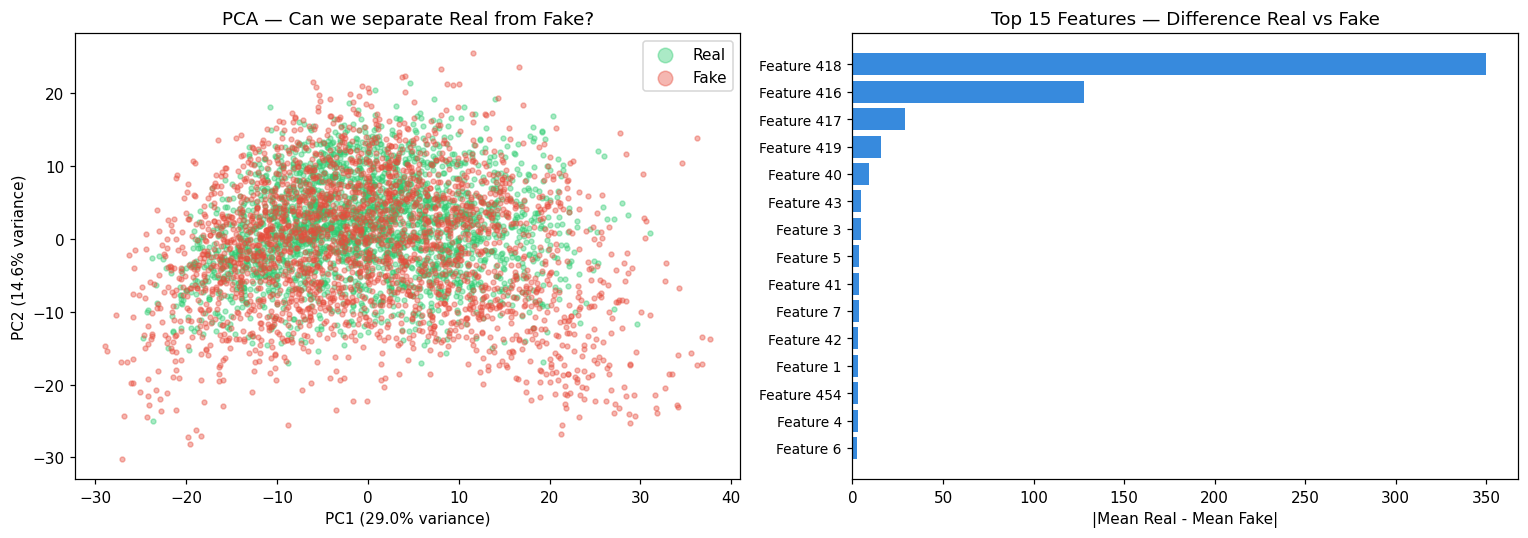

PCA explains 43.7% of variance in 2 components
If clusters are separable → our features are useful for classification!


In [17]:
# ── CELL 15: Feature distribution — real vs fake ──────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# PCA to visualise high-dimensional features in 2D
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA scatter
real_mask = y_train == 0
fake_mask = y_train == 1
axes[0].scatter(X_pca[real_mask, 0], X_pca[real_mask, 1],
                c='#2ECC71', alpha=0.4, s=10, label='Real')
axes[0].scatter(X_pca[fake_mask, 0], X_pca[fake_mask, 1],
                c='#E74C3C', alpha=0.4, s=10, label='Fake')
axes[0].set_title('PCA — Can we separate Real from Fake?', fontsize=12)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
axes[0].legend(markerscale=3)

# Feature importance — which features differ most between real/fake
real_mean = X_train[real_mask].mean(axis=0)
fake_mean = X_train[fake_mask].mean(axis=0)
diff = np.abs(real_mean - fake_mean)
top_feat_idx = np.argsort(diff)[::-1][:15]

axes[1].barh(range(15), diff[top_feat_idx][::-1], color='#378ADD')
axes[1].set_title('Top 15 Features — Difference Real vs Fake', fontsize=12)
axes[1].set_xlabel('|Mean Real - Mean Fake|')
axes[1].set_yticks(range(15))
axes[1].set_yticklabels([f'Feature {i}' for i in top_feat_idx[::-1]], fontsize=9)

plt.tight_layout()
plt.show()

explained = pca.explained_variance_ratio_.sum() * 100
print(f'PCA explains {explained:.1f}% of variance in 2 components')
print('If clusters are separable → our features are useful for classification!')

---
## Step 6 — Save Features to Drive

We save the extracted features (~50MB) so we never need to re-process 7GB of audio again.
Week 2 will load these directly.

In [18]:
# ── CELL 16: Save features and reproducibility metadata to Drive ───────────
SAVE_DIR = '/content/drive/MyDrive/voiceguard'
os.makedirs(SAVE_DIR, exist_ok=True)

np.save(f'{SAVE_DIR}/X_train.npy', X_train)
np.save(f'{SAVE_DIR}/y_train.npy', y_train)
np.save(f'{SAVE_DIR}/X_dev.npy', X_dev)
np.save(f'{SAVE_DIR}/y_dev.npy', y_dev)
np.save(f'{SAVE_DIR}/ids_train.npy', np.asarray(ids_train, dtype=str))
np.save(f'{SAVE_DIR}/ids_dev.npy', np.asarray(ids_dev, dtype=str))

# Fit scaler only on training features. Reuse it in Week 2; never fit on dev/test.
with open(f'{SAVE_DIR}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

metadata = {
    'dataset': 'ASVspoof 2019 Logical Access',
    'label_mapping': {'bonafide': 0, 'spoof': 1},
    'feature_type': 'statistical MFCC/delta/log-mel/spectral/chroma/energy summary',
    'n_features': int(X_train.shape[1]),
    'n_train': int(len(X_train)),
    'n_dev': int(len(X_dev)),
    'sample_rate_hz': 16000,
    'duration_seconds': 4,
    'train_bonafide': int((y_train == 0).sum()),
    'train_spoof': int((y_train == 1).sum()),
    'dev_bonafide': int((y_dev == 0).sum()),
    'dev_spoof': int((y_dev == 1).sum()),
    'random_seed_train': 42,
    'random_seed_dev': 43
}
with open(f'{SAVE_DIR}/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

saved_files = [
    'X_train.npy', 'y_train.npy', 'X_dev.npy', 'y_dev.npy',
    'ids_train.npy', 'ids_dev.npy', 'scaler.pkl', 'metadata.json'
]
print('Saved to Google Drive:')
for fname in saved_files:
    size_mb = os.path.getsize(os.path.join(SAVE_DIR, fname)) / 1024**2
    print(f'  {fname:<20} {size_mb:.2f} MB')
print('\nReminder: these are summary features for a baseline model. A CNN needs time-frequency spectrogram tensors, which we will add separately.')


Saved to Google Drive:
  X_train.npy          8.68 MB
  y_train.npy          0.04 MB
  X_dev.npy            3.47 MB
  y_dev.npy            0.02 MB
  ids_train.npy        0.23 MB
  ids_dev.npy          0.09 MB
  scaler.pkl           0.01 MB
  metadata.json        0.00 MB

Reminder: these are summary features for a baseline model. A CNN needs time-frequency spectrogram tensors, which we will add separately.


---
## Week 1 — Current deliverables and caveats

| Step | Output |
|---|---|
| Dataset | ASVspoof 2019 Logical Access (LA) |
| EDA | Class counts, waveform, mel spectrogram and MFCC plots |
| Baseline features | Fixed-length statistical feature vectors |
| Training subset | Random, class-balanced subset (configurable) |
| Development subset | Random sample preserving natural class ratio |
| Saved artifacts | Features, labels, file IDs, scaler and metadata in Google Drive |

**Important:** completing this notebook does not yet mean the real-time deepfake detector is trained. Week 2 will train and evaluate a baseline model. The CNN requires a separate time-frequency tensor pipeline. Do not claim an EER or accuracy until it has been measured on a properly held-out evaluation set.

### Next: Week 2 — Model Training
- Baseline: Logistic Regression with training-only scaling
- Main model: CNN on log-mel spectrograms
- Metrics: EER, ROC-AUC, precision/recall and confusion matrix
- Evaluate generalization; do not treat a target EER as an achieved result
